# VALORA AI: Price ranges and prediction uncertainty (exploratory)

**Question (to be confirmed by the student):** *How accurately can we estimate apartment asking prices in Montenegro, and how reliably can we quantify the uncertainty of these predictions?*

**Status:**
- Exploratory cross-validation research, carried out after the Capstone was completed.
- Only the 1,098 **development** listings and the existing 5 group-aware folds are used. The 278 test listings are never loaded.
- The plan and the selection rule were fixed in advance: `EXPERIMENT_PLAN.md`.
- The final project, `research_extension` and `research_opportunities` are not changed.

## 1. Summary

All results below are **exploratory cross-validation findings** on the 1,098 development listings (5 group-aware folds; test set unused).

- **Honest 80% ranges are possible, but they are wide.**
  - The chosen method, **linear quantile regression on log price (G3a)**, covers **78.9%** of out-of-fold listings (fold range 75–84%).
  - Its median width is **64% of the central estimate**. The pre-set label for that is *moderate*.
  - At 90% it covers 89.0%, with a median width of 85%.
- **Where the ranges are reliable:** G3a's coverage is **similar in every city** (0.78–0.81 for cities with ≥ 20 listings).
- **Where they are narrow:** in continental cities (median width ≈ 40–55%: Nikšić, Cetinje, Podgorica, Kolašin). On the coast they are wide (≈ 80–97%: Herceg Novi, Budva, Tivat).
- **The simplest method is close behind.** Empirical city €/m² quantiles × area (G1) reaches 77.9% coverage with 58% median width. Under the pre-registered rule it is slightly worse on interval score (paired +€10.8k, SE €7.6k).
- **Conformal intervals around the rule (G2a–c)** reach about 80% overall, but because one width fits all, they **over-cover Podgorica (≈ 0.87–0.90) and under-cover the coastal cities (≈ 0.65–0.80)**.
  - CQR (G4a/b) adds little over the already well-calibrated linear quantile regression.
  - CQR does repair the under-covering quantile gradient boosting (74.6% → 81.5%), at the cost of width.
- **Expensive flats remain the weak point.** For flats ≥ €500k (n = 46), G3a covers **50%**, and the other half lies **above** the upper bound. Cheap flats (< €100k, n = 92) are covered only 60% of the time.
- **Manual-review screening:** it finds the gross errors already found by hand, but adds little. The flags are dominated by legitimately extreme prices and agree with the student's own check flags in only 1 of 24 cases. **Not recommended beyond a short mention.**

## 2. How the research question developed

| Phase | Question | Status |
|---|---|---|
| Original student project | Can ML estimate apartment asking prices in Montenegro? | Answered in the final Capstone |
| Research extension | Can ML improve on a simple city €/m² rule, and how much does location quality contribute? | Answered: no reliable ML gain; location matters most |
| Opportunity audit | Which other questions can these data answer? | Price ranges ranked first |
| **This phase** | **How reliably can we quantify the uncertainty of the estimates?** | **Formulated after the earlier results; exploratory** |

The interval question did **not** exist when the data were first analysed. It is presented as a follow-up, not as a hypothesis set in advance.

## 3. Setup, data and folds

**What this code does:** Loads the frozen processed data and the fold assignment from the final project (read-only). It checks that no test listing is present and that the folds are exactly the final project's folds.

**Why we need it:** All methods must be compared on the same listings and folds. The test listings must play no role in this phase.

In [1]:
import sys, json, hashlib, time
from pathlib import Path
sys.dont_write_bytecode = True
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mticker
from IPython.display import display
HERE = Path.cwd() if (Path.cwd() / 'lib').is_dir() else Path.cwd().parent
FINAL = HERE.parent / 'valora_ai'
sys.path.insert(0, str(HERE / 'lib'))
import valora_prep as vp, valora_model as vm, valora_plot as vplot, ux
vplot.apply_style(); pd.set_option('display.width', 190); pd.set_option('display.max_columns', 30)
RES, FIG = HERE / 'results', HERE / 'figures'

data = pd.read_csv(FINAL / 'data' / 'processed' / 'valora_apartments_clean.csv')
folds_df = pd.read_csv(FINAL / 'docs' / 'results' / 'cv_folds.csv')
split = pd.read_csv(FINAL / 'docs' / 'results' / 'split_assignment.csv')
dev = folds_df[['record_id', 'cv_fold']].merge(data, on='record_id', how='left')
test_ids = set(split.loc[split['split'] == 'test', 'record_id'])
assert len(dev) == 1098 and not set(dev['record_id']) & test_ids and dev['population'].eq('primary').all()
fp = hashlib.sha256(json.dumps([dev.loc[dev['cv_fold'] == k, 'record_id'].tolist() for k in range(5)]).encode()).hexdigest()[:12]
assert fp == 'dd9f21b7d8b6'
COASTAL = {'Herceg Novi', 'Kotor', 'Tivat', 'Budva', 'Bar', 'Ulcinj'}
dev['region'] = dev['city_clean'].map(lambda c: 'Unknown' if c == 'Unknown' else ('coastal' if c in COASTAL else 'continental'))
y = dev['price_eur'].to_numpy(float)
print(f'Development listings: {len(dev)} | test listings used: 0 | fold fingerprint {fp} (matches final project)')
print('Region:', dev['region'].value_counts().to_dict())

Development listings: 1098 | test listings used: 0 | fold fingerprint dd9f21b7d8b6 (matches final project)
Region: {'coastal': 579, 'continental': 492, 'Unknown': 27}


## 4. The eight interval methods

| ID | Idea in plain words |
|---|---|
| **G1** | Use the range of **€/m² seen in the city** (the 10th–90th percentile for an 80% range) and multiply by the area |
| **G2a** | Take the city rule's estimate, and add ± the error size that 80% of **calibration** flats stayed within (in euros) |
| **G2b** | The same, but the error is measured **relative** to the estimate (± X%) |
| **G2c** | The same, on the **log scale**, so the range is wider above than below (× / ÷ a factor) |
| **G3a** | A **linear quantile regression** directly predicts the 10th and 90th percentile of the (log) price |
| **G3b** | A **quantile gradient-boosting** model predicts the same percentiles, allowing non-linear effects |
| **G4a / G4b** | **Conformalized quantile regression (CQR):** G3a / G3b, widened or narrowed using a separate calibration set |

**What "split conformal" means:**
- Inside each outer training fold, about 25% of the listings (whole repeat groups) are set aside for **calibration**.
- The rule or model learns from the remaining 75%.
- The calibration errors decide how wide the interval must be.
- The outer-validation listings are only used to **evaluate**.

**What this code does:** Runs all eight methods at 80% and 90% nominal coverage on the 5 outer folds. It stores every out-of-fold interval and computes the metrics fixed in the plan for each fold.

**Why we need it:** This is the core experiment: every method is evaluated on exactly the same unseen listings.

In [2]:
METHODS = list(ux.LABELS)
LEVELS = {0.80: 0.20, 0.90: 0.10}
OOF = {(m, lv): {'lo': np.full(len(dev), np.nan), 'hi': np.full(len(dev), np.nan), 'c': np.full(len(dev), np.nan)} for m in METHODS for lv in LEVELS}
fold_rows, timings, n_fit = [], {}, {}
for m in METHODS:
    t0 = time.perf_counter()
    for lv, alpha in LEVELS.items():
        for k in range(5):
            tr, va = dev[dev['cv_fold'] != k], dev[dev['cv_fold'] == k]
            lo, hi, c = ux.predict_interval(m, tr, va, alpha)
            idx = va.index.to_numpy()
            OOF[(m, lv)]['lo'][idx], OOF[(m, lv)]['hi'][idx], OOF[(m, lv)]['c'][idx] = lo, hi, c
            fold_rows.append({'method': m, 'level': lv, 'fold': k, **ux.interval_metrics(y[idx], lo, hi, c, alpha)})
            if lv == 0.80:
                n_fit.setdefault(m, []).append(len(ux.fit_cal_split(tr)[0]) if m in ('G2a', 'G2b', 'G2c', 'G4a', 'G4b') else len(tr))
    timings[m] = time.perf_counter() - t0
    print(f'{m:4} {ux.LABELS[m]:32} done in {timings[m]:.1f}s | listings used for fitting per fold: {n_fit[m]}')
F = pd.DataFrame(fold_rows); F.to_csv(RES / 'fold_metrics.csv', index=False)
print('Quantile crossings (bounds swapped):', ux.QCROSS['count'])
assert all(np.isfinite(OOF[k]['lo']).all() and np.isfinite(OOF[k]['hi']).all() for k in OOF)

G1   Empirical city €/m² quantiles    done in 0.1s | listings used for fitting per fold: [885, 880, 873, 876, 878]


G2a  Conformal, absolute residual     done in 0.2s | listings used for fitting per fold: [661, 665, 657, 662, 665]


G2b  Conformal, relative residual     done in 0.1s | listings used for fitting per fold: [661, 665, 657, 662, 665]
G2c  Conformal, log residual          done in 0.1s | listings used for fitting per fold: [661, 665, 657, 662, 665]


G3a  Linear quantile regression       done in 2.4s | listings used for fitting per fold: [885, 880, 873, 876, 878]


G3b  Quantile gradient boosting       done in 9.6s | listings used for fitting per fold: [885, 880, 873, 876, 878]


G4a  CQR on linear QR                 done in 1.5s | listings used for fitting per fold: [661, 665, 657, 662, 665]


G4b  CQR on quantile GB               done in 9.3s | listings used for fitting per fold: [661, 665, 657, 662, 665]
Quantile crossings (bounds swapped): 0


## 5. Results and model choice

**What this code does:** Summarises the fold metrics (mean ± std over the 5 folds) at 80% and 90%. It adds group-level coverage (each repeat group counted once) and applies the selection rule fixed in the plan.

**Why we need it:** The selection rule weighs coverage, width (through the interval score) and simplicity, and it was fixed before the results were known.

In [3]:
def summarise(lv):
    f = F[F['level'] == lv]
    s = f.groupby('method').agg(coverage=('coverage', 'mean'), coverage_std=('coverage', 'std'), mean_width=('mean_width', 'mean'),
                                median_width=('median_width', 'mean'), median_rel_width=('median_rel_width', 'mean'),
                                interval_score=('interval_score', 'mean'), interval_score_std=('interval_score', 'std'),
                                pinball=('pinball', 'mean'), central_mae=('central_mae', 'mean'),
                                miss_above=('miss_above_%', 'mean'), miss_below=('miss_below_%', 'mean')).reindex(METHODS)
    cov = {m: ((y >= OOF[(m, lv)]['lo']) & (y <= OOF[(m, lv)]['hi'])) for m in METHODS}
    s['group_coverage'] = [pd.Series(cov[m]).groupby(dev['repeat_group'].to_numpy()).mean().mean() for m in METHODS]
    s['complexity'] = s.index.map(ux.COMPLEXITY); s['label'] = s.index.map(ux.LABELS)
    s['fit_time_s'] = s.index.map(timings)
    return s
S80, S90 = summarise(0.80), summarise(0.90)
S80.to_csv(RES / 'summary_80.csv'); S90.to_csv(RES / 'summary_90.csv')
fmt = {'coverage': 3, 'coverage_std': 3, 'group_coverage': 3, 'mean_width': 0, 'median_width': 0, 'median_rel_width': 3,
       'interval_score': 0, 'interval_score_std': 0, 'pinball': 0, 'central_mae': 0, 'miss_above': 1, 'miss_below': 1, 'fit_time_s': 1}
print('=== 80% intervals'); display(S80.round(fmt))
print('=== 90% intervals'); display(S90.round(fmt))

# selection rule (plan section "Selection rule")
acc = S80[(S80['coverage'] >= 0.77) & (S80['coverage'] <= 0.83)]
if len(acc):
    best = acc['interval_score'].idxmin()
    f80 = F[F['level'] == 0.80].pivot(index='fold', columns='method', values='interval_score')
    rows = []
    for m in acc.index:
        d = f80[m] - f80[best]
        rows.append({'method': m, 'paired_diff_vs_best': d.mean(), 'se': d.std(ddof=1) / np.sqrt(5)})
    pdiff = pd.DataFrame(rows).set_index('method')
    eligible = [m for m in acc.index if m == best or pdiff.loc[m, 'paired_diff_vs_best'] <= pdiff.loc[m, 'se']]
    CHOSEN = sorted(eligible, key=lambda m: (ux.COMPLEXITY[m], S80.loc[m, 'interval_score']))[0]
    display(pdiff.round(0))
else:
    best, eligible = None, []
    CHOSEN = (S80['coverage'] - 0.80).abs().idxmin()
sel = {'acceptable_80': list(acc.index), 'best_interval_score': best, 'eligible_within_1SE': eligible, 'chosen': CHOSEN}
json.dump(sel, open(RES / 'selection.json', 'w'), indent=2)
print('Selection:', sel)

=== 80% intervals


,coverage,coverage_std,mean_width,median_width,median_rel_width,interval_score,interval_score_std,pinball,central_mae,miss_above,miss_below,group_coverage,complexity,label,fit_time_s
method,,,,,,,,,,,,,,,
G1,0.779,0.030,145339.0,116324.0,0.580,261265.0,41622.0,13063.0,50527.0,11.1,11.0,0.776,1,Empirical city €/m² quantiles,0.1
G2a,0.805,0.029,133641.0,133729.0,0.721,318016.0,51606.0,15901.0,51078.0,11.4,8.1,0.793,1,"Conformal, absolute residual",0.2
G2b,0.799,0.062,133504.0,117794.0,0.635,276616.0,43671.0,13831.0,51078.0,13.0,7.1,0.793,1,"Conformal, relative residual",0.1
G2c,0.804,0.058,143525.0,126547.0,0.683,273093.0,43947.0,13655.0,51078.0,10.3,9.3,0.795,1,"Conformal, log residual",0.1
G3a,0.789,0.036,155866.0,118156.0,0.643,250429.0,32919.0,12521.0,50855.0,10.8,10.3,0.787,2,Linear quantile regression,2.4
G3b,0.746,0.024,151440.0,119359.0,0.649,273758.0,24089.0,13688.0,54754.0,12.7,12.7,0.741,3,Quantile gradient boosting,9.6
G4a,0.806,0.052,170257.0,127446.0,0.676,256899.0,28244.0,12845.0,50968.0,8.9,10.4,0.802,2,CQR on linear QR,1.5
G4b,0.815,0.041,188141.0,150087.0,0.785,289360.0,17635.0,14468.0,57672.0,8.6,10.0,0.810,3,CQR on quantile GB,9.3


=== 90% intervals


,coverage,coverage_std,mean_width,median_width,median_rel_width,interval_score,interval_score_std,pinball,central_mae,miss_above,miss_below,group_coverage,complexity,label,fit_time_s
method,,,,,,,,,,,,,,,
G1,0.879,0.021,190863.0,151771.0,0.785,337273.0,79274.0,8432.0,50527.0,6.2,5.9,0.875,1,Empirical city €/m² quantiles,0.1
G2a,0.907,0.020,217039.0,219417.0,1.186,472189.0,92549.0,11805.0,51078.0,6.2,3.1,0.900,1,"Conformal, absolute residual",0.2
G2b,0.900,0.017,187987.0,165777.0,0.895,380128.0,78115.0,9503.0,51078.0,8.6,1.4,0.893,1,"Conformal, relative residual",0.1
G2c,0.915,0.025,203468.0,179466.0,0.967,358897.0,81470.0,8972.0,51078.0,4.9,3.6,0.909,1,"Conformal, log residual",0.1
G3a,0.890,0.018,215699.0,154837.0,0.854,311616.0,56254.0,7790.0,50855.0,5.5,5.6,0.885,2,Linear quantile regression,2.4
G3b,0.845,0.011,202429.0,152188.0,0.858,343130.0,42760.0,8578.0,54754.0,7.7,7.8,0.842,3,Quantile gradient boosting,9.6
G4a,0.916,0.027,241693.0,173029.0,0.940,312527.0,31983.0,7813.0,50968.0,3.8,4.6,0.914,2,CQR on linear QR,1.5
G4b,0.896,0.037,250110.0,185516.0,1.038,354969.0,38791.0,8874.0,57672.0,4.2,6.2,0.894,3,CQR on quantile GB,9.3


,paired_diff_vs_best,se
method,,
G1,10836.0,7640.0
G2a,67587.0,11594.0
G2b,26187.0,8398.0
G2c,22664.0,8514.0
G3a,0.0,0.0
G4a,6470.0,3374.0
G4b,38931.0,8923.0


Selection: {'acceptable_80': ['G1', 'G2a', 'G2b', 'G2c', 'G3a', 'G4a', 'G4b'], 'best_interval_score': 'G3a', 'eligible_within_1SE': ['G3a'], 'chosen': 'G3a'}


**What this code does:** Draws coverage against median relative width for all methods at 80% and 90%, with the target coverage marked.

**Why we need it:** Shows the trade-off at a glance: up and left is better (more reliable and narrower).

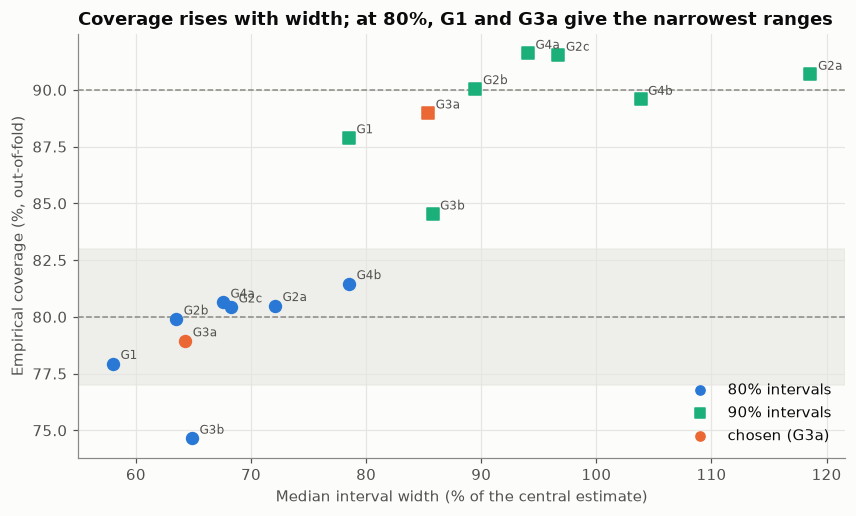

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for lv, S, mk in [(0.80, S80, 'o'), (0.90, S90, 's')]:
    for m in METHODS:
        col = vplot.ORANGE if m == CHOSEN else (vplot.BLUE if lv == 0.80 else vplot.AQUA)
        ax.scatter(100 * S.loc[m, 'median_rel_width'], 100 * S.loc[m, 'coverage'], marker=mk, s=60, color=col, zorder=3)
        ax.annotate(m, (100 * S.loc[m, 'median_rel_width'], 100 * S.loc[m, 'coverage']), xytext=(5, 3), textcoords='offset points', fontsize=8, color=vplot.INK_2)
    ax.axhline(100 * lv, color=vplot.INK_3, ls='--', lw=1)
ax.axhspan(77, 83, color=vplot.GRID, alpha=0.6, zorder=0)
ax.scatter([], [], marker='o', color=vplot.BLUE, label='80% intervals'); ax.scatter([], [], marker='s', color=vplot.AQUA, label='90% intervals')
ax.scatter([], [], marker='o', color=vplot.ORANGE, label=f'chosen ({CHOSEN})')
ax.set_xlabel('Median interval width (% of the central estimate)'); ax.set_ylabel('Empirical coverage (%, out-of-fold)')
ax.set_title('Coverage rises with width; at 80%, G1 and G3a give the narrowest ranges'); ax.legend(loc='lower right')
vplot.save(fig, FIG, 'ux_01_coverage_vs_width'); plt.show()

**What it means** (80% intervals; mean over 5 folds):

| Method | Coverage (± std) | Median width (% of estimate) | Interval score | Central MAE | Data used for fitting |
|---|---|---|---|---|---|
| **G3a Linear quantile regression (chosen)** | **78.9% (± 3.6)** | **64%** | **€250k** | €50,855 | ≈ 880 |
| G4a CQR on linear QR | 80.6% (± 5.2) | 68% | €257k | €50,968 | ≈ 660 + 220 calibration |
| G1 Empirical city €/m² quantiles | 77.9% (± 3.0) | 58% | €261k | €50,527 | ≈ 880 |
| G2c Conformal, log residual | 80.4% (± 5.8) | 68% | €273k | €51,078 | ≈ 660 + 220 |
| G3b Quantile gradient boosting | **74.6%** (± 2.4), below acceptable | 65% | €274k | €54,754 | ≈ 880 |
| G2b Conformal, relative residual | 79.9% (± 6.2) | 64% | €277k | €51,078 | ≈ 660 + 220 |
| G4b CQR on quantile GB | 81.5% (± 4.1) | 79% | €289k | €57,672 | ≈ 660 + 220 |
| G2a Conformal, absolute residual | 80.5% (± 2.9) | 72% | €318k | €51,078 | ≈ 660 + 220 |

- **Selection (pre-registered):**
  - Seven methods reach acceptable coverage (77–83%).
  - G3a has the lowest interval score, and no other method is within one paired standard error of it (G4a +€6.5k, SE €3.4k; G1 +€10.8k, SE €7.6k).
  - So G3a is chosen even though it is more complex than G1.
- **Width alone did not decide.** G1 is narrower than G3a, but it misses more often and more severely, which shows in its interval score.
- **The central estimate stays the same:** G3a's median prediction has CV MAE €50,855, practically equal to the city rule (€50,527). Quantile regression adds **range information**, not a better point estimate.
- **Quantile crossing:** none occurred in any fold or level.
- **Calibration costs data:** split-conformal methods fit on about 75% of each training fold (≈ 660 listings instead of ≈ 880).
- **At 90%:** G3a covers 89.0% (median width 85%). G1 falls short (87.9%). The conformal methods reach 90–92%, but they are much wider (89–119%).

## 6. Actual prices and their intervals

**What this code does:** Plots every development listing's actual asking price against the chosen method's out-of-fold 80% interval, sorted by the central estimate.

**Why we need it:** Shows what an 80% range looks like in euros, and where the misses are.

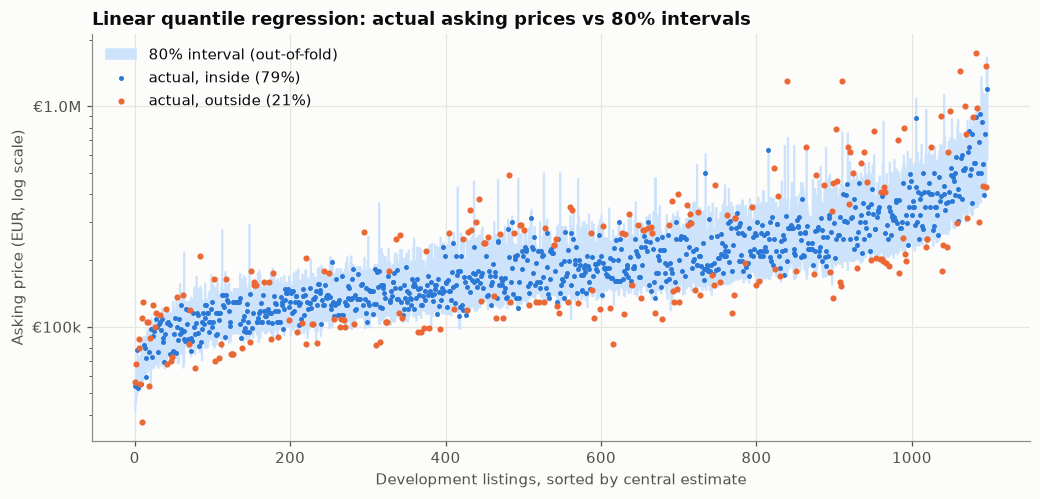

In [5]:
o = OOF[(CHOSEN, 0.80)]; order = np.argsort(o['c'])
fig, ax = plt.subplots(figsize=(11, 4.8))
xs = np.arange(len(dev))
ax.fill_between(xs, o['lo'][order], o['hi'][order], color='#cde2fb', step='mid', label='80% interval (out-of-fold)')
inside = ((y >= o['lo']) & (y <= o['hi']))[order]
ax.scatter(xs[inside], y[order][inside], s=5, color=vplot.BLUE, label=f'actual, inside ({inside.mean():.0%})')
ax.scatter(xs[~inside], y[order][~inside], s=9, color=vplot.ORANGE, label=f'actual, outside ({(~inside).mean():.0%})')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro)); ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel('Development listings, sorted by central estimate'); ax.set_ylabel('Asking price (EUR, log scale)')
ax.set_title(f'{ux.LABELS[CHOSEN]}: actual asking prices vs 80% intervals'); ax.legend(loc='upper left')
vplot.save(fig, FIG, 'ux_02_actual_vs_intervals'); plt.show()

## 7. Geographical reliability

**What this code does:** For every city with at least 20 development listings, and for coastal vs continental, computes the 80% coverage and median relative width of the chosen method and of all eight methods (with n).

**Why we need it:** A global 80% does not guarantee 80% in every city. Users in a given city need to know whether the range is trustworthy there.

In [6]:
def by_group(col, lv=0.80, methods=METHODS, min_n=20):
    out = []
    for g, idx in dev.groupby(col).groups.items():
        idx = np.asarray(idx)
        if len(idx) < min_n: continue
        for m in methods:
            o = OOF[(m, lv)]
            out.append({col: g, 'n': len(idx), 'method': m, 'coverage': np.mean((y[idx] >= o['lo'][idx]) & (y[idx] <= o['hi'][idx])),
                        'median_rel_width': np.median((o['hi'][idx] - o['lo'][idx]) / o['c'][idx]), 'median_width_eur': np.median(o['hi'][idx] - o['lo'][idx])})
    return pd.DataFrame(out)
city = by_group('city_clean'); region = by_group('region', min_n=1)
city.to_csv(RES / 'by_city_80.csv', index=False); region.to_csv(RES / 'by_region_80.csv', index=False)
print('Coverage by city (80%):'); display(city.pivot(index=['city_clean', 'n'], columns='method', values='coverage').round(2))
print('Median relative width by city (80%):'); display(city.pivot(index=['city_clean', 'n'], columns='method', values='median_rel_width').round(2))
print('Region (80%):'); display(region.pivot(index=['region', 'n'], columns='method', values='coverage').round(2)); display(region.pivot(index=['region', 'n'], columns='method', values='median_rel_width').round(2))

Coverage by city (80%):


,method,G1,G2a,G2b,G2c,G3a,G3b,G4a,G4b
city_clean,n,,,,,,,,
Bar,62,0.76,0.87,0.84,0.81,0.79,0.77,0.82,0.89
Budva,184,0.80,0.71,0.74,0.76,0.81,0.76,0.84,0.83
Cetinje,27,0.74,1.00,0.93,0.93,0.81,0.44,0.85,0.48
Herceg Novi,180,0.79,0.69,0.74,0.75,0.78,0.74,0.80,0.83
Kolašin,41,0.80,0.90,0.85,0.83,0.78,0.88,0.83,0.85
Kotor,46,0.76,0.65,0.80,0.76,0.78,0.70,0.76,0.83
Nikšić,24,0.71,0.79,0.71,0.67,0.79,0.46,0.83,0.54
Podgorica,389,0.80,0.90,0.87,0.89,0.79,0.76,0.81,0.85
Tivat,62,0.77,0.68,0.74,0.77,0.79,0.77,0.73,0.76


Median relative width by city (80%):


,method,G1,G2a,G2b,G2c,G3a,G3b,G4a,G4b
city_clean,n,,,,,,,,
Bar,62,0.60,0.85,0.64,0.71,0.58,0.52,0.64,0.80
Budva,184,0.87,0.64,0.64,0.71,0.83,0.71,0.93,0.91
Cetinje,27,0.40,1.23,0.64,0.71,0.45,0.87,0.47,1.05
Herceg Novi,180,0.83,0.59,0.64,0.71,0.83,0.81,0.90,0.91
Kolašin,41,0.53,1.01,0.64,0.71,0.54,0.84,0.59,0.85
Kotor,46,0.60,0.51,0.64,0.68,0.66,0.93,0.70,1.03
Nikšić,24,0.37,0.98,0.63,0.71,0.40,0.91,0.58,1.01
Podgorica,389,0.51,0.79,0.64,0.71,0.52,0.44,0.56,0.56
Tivat,62,0.95,0.54,0.64,0.71,0.97,0.67,0.84,1.08


Region (80%):


,method,G1,G2a,G2b,G2c,G3a,G3b,G4a,G4b
region,n,,,,,,,,
Unknown,27,0.52,0.56,0.48,0.44,0.74,0.74,0.74,0.70
coastal,579,0.78,0.73,0.76,0.77,0.79,0.75,0.80,0.82
continental,492,0.79,0.90,0.86,0.87,0.79,0.74,0.82,0.81


,method,G1,G2a,G2b,G2c,G3a,G3b,G4a,G4b
region,n,,,,,,,,
Unknown,27,0.77,0.63,0.68,0.73,2.01,1.01,2.61,1.15
coastal,579,0.84,0.65,0.64,0.71,0.80,0.73,0.84,0.93
continental,492,0.51,0.84,0.64,0.71,0.52,0.51,0.56,0.61


**What this code does:** Draws the chosen method's coverage and median relative width per city, next to the simplest baseline G1.

**Why we need it:** A visual check of where the ranges are reliable and how wide they are.

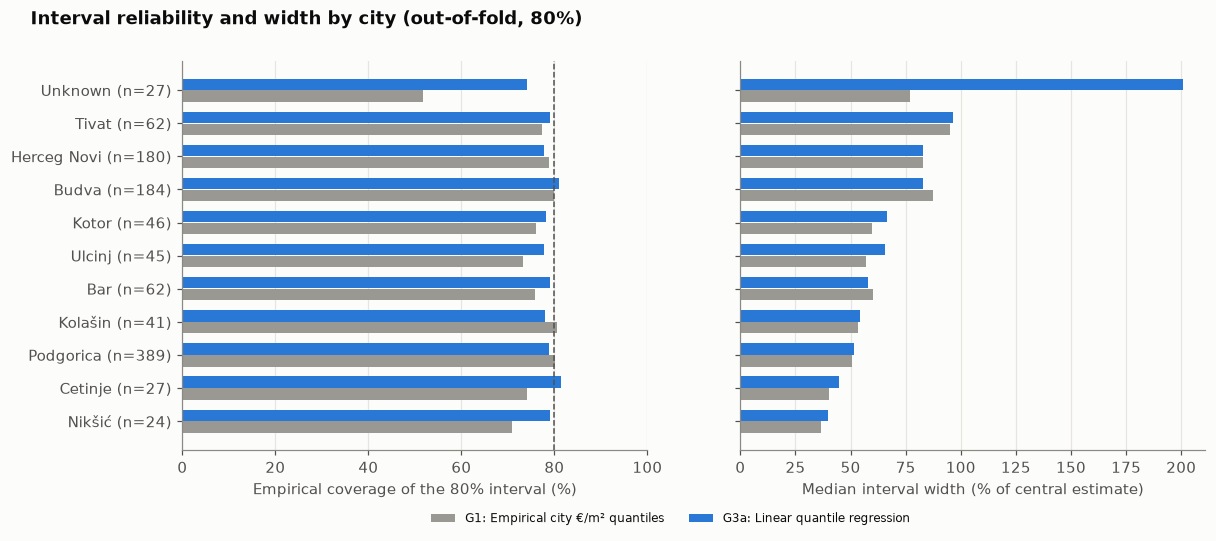

In [7]:
cc = city[city['method'].isin([CHOSEN, 'G1'])].copy()
order = cc[cc['method'] == CHOSEN].sort_values('median_rel_width')['city_clean'].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
yy = np.arange(len(order))
for off, m, col in [(-0.18, 'G1', vplot.GRAY), (0.18, CHOSEN, vplot.BLUE)] if CHOSEN != 'G1' else [(0, 'G1', vplot.BLUE)]:
    d = cc[cc['method'] == m].set_index('city_clean').reindex(order)
    axes[0].barh(yy + off, 100 * d['coverage'], height=0.34, color=col, label=f'{m}: {ux.LABELS[m]}')
    axes[1].barh(yy + off, 100 * d['median_rel_width'], height=0.34, color=col)
axes[0].axvline(80, color=vplot.INK_2, ls='--', lw=1); axes[0].set_xlim(0, 100)
n_map = cc.drop_duplicates('city_clean').set_index('city_clean')['n']
axes[0].set_yticks(yy, [f'{c} (n={n_map[c]})' for c in order])
axes[0].set_xlabel('Empirical coverage of the 80% interval (%)'); axes[1].set_xlabel('Median interval width (% of central estimate)')
axes[0].legend(loc='upper center', bbox_to_anchor=(1.05, -0.13), ncols=2, fontsize=8)
for a in axes: a.grid(axis='y', visible=False)
fig.suptitle('Interval reliability and width by city (out-of-fold, 80%)', x=0.01, ha='left', fontweight='bold')
vplot.save(fig, FIG, 'ux_03_city_coverage_width'); plt.show()

**What it means** (80% intervals, out-of-fold; n per city):

| City | n | G3a coverage | G3a median width | G1 coverage | G2c coverage |
|---|---|---|---|---|---|
| Nikšić | 24 | 0.79 | **40%** | 0.71 | 0.67 |
| Cetinje | 27 | 0.81 | 45% | 0.74 | 0.93 |
| Podgorica | 389 | 0.79 | 52% | 0.80 | 0.89 |
| Kolašin | 41 | 0.78 | 54% | 0.80 | 0.83 |
| Bar | 62 | 0.79 | 58% | 0.76 | 0.81 |
| Kotor | 46 | 0.78 | 66% | 0.76 | 0.76 |
| Ulcinj | 45 | 0.78 | 66% | 0.73 | 0.80 |
| Budva | 184 | 0.81 | 83% | 0.80 | 0.76 |
| Herceg Novi | 180 | 0.78 | 83% | 0.79 | 0.75 |
| Tivat | 62 | 0.79 | **97%** | 0.77 | 0.77 |
| Unknown city | 27 | 0.74 | 201% | 0.52 | 0.44 |

- **Reliability is even across cities for G3a.** Every city with ≥ 20 listings is between 0.78 and 0.81. G1 and the conformal methods vary much more, because their width does not adapt (or adapts only through the city's €/m² spread).
- **Informativeness differs strongly:**
  - continental cities: median width 40–55% (≈ ±20–27%);
  - coastal cities: 58–97%;
  - Tivat, Budva and Herceg Novi: 80–97%.
  - **Region:** continental coverage 0.79 at 52% width; coastal 0.79 at 80% width.
- **Unknown city:** the ranges are extremely wide (median 201%), which honestly reflects missing location.
- **Small samples:** Nikšić (24) and Cetinje (27) are too small for firm city-level conclusions. A coverage of 0.79 on 24 listings could easily be 0.65 or 0.90 on another sample.
- **No guarantee per city:** 80% overall does not guarantee 80% in every city, nor for any single flat.

## 8. High-price and large apartments

**What this code does:** Splits the out-of-fold results by **actual** price band and size band. It shows coverage, misses above and below the interval, and relative width for the chosen method and the main alternatives. The actual price is used **only** for this analysis afterwards, never to build an interval.

**Why we need it:** The previous research showed that expensive flats are strongly underestimated. Here we check whether intervals at least capture them, and whether absolute and relative intervals behave differently.

In [8]:
dev['price_band'] = pd.cut(dev['price_eur'], [0, 100_000, 200_000, 300_000, 500_000, np.inf], labels=['<100k', '100–200k', '200–300k', '300–500k', '≥500k'])
dev['size_band'] = pd.cut(dev['area_m2'], [0, 40, 60, 80, 120, np.inf], labels=['<40', '40–60', '60–80', '80–120', '≥120'])
SHOW = list(dict.fromkeys([CHOSEN, 'G1', 'G2a', 'G2c', 'G4a', 'G4b']))
rows = []
for band_col in ['price_band', 'size_band']:
    for b, idx in dev.groupby(band_col, observed=True).groups.items():
        idx = np.asarray(idx)
        for m in SHOW:
            o = OOF[(m, 0.80)]
            rows.append({'by': band_col, 'band': str(b), 'n': len(idx), 'method': m,
                         'coverage': np.mean((y[idx] >= o['lo'][idx]) & (y[idx] <= o['hi'][idx])),
                         'miss_above_%': 100 * np.mean(y[idx] > o['hi'][idx]), 'miss_below_%': 100 * np.mean(y[idx] < o['lo'][idx]),
                         'median_rel_width': np.median((o['hi'][idx] - o['lo'][idx]) / o['c'][idx]),
                         'median_width_eur': np.median(o['hi'][idx] - o['lo'][idx])})
HP = pd.DataFrame(rows); HP.to_csv(RES / 'high_price_analysis_80.csv', index=False)
for b in ['price_band', 'size_band']:
    print(f'--- {b}: coverage'); display(HP[HP['by'] == b].pivot(index=['band', 'n'], columns='method', values='coverage').round(2))
    print(f'--- {b}: % of listings ABOVE the upper bound'); display(HP[HP['by'] == b].pivot(index=['band', 'n'], columns='method', values='miss_above_%').round(0))
print('--- price_band: median width (EUR)'); display(HP[HP['by'] == 'price_band'].pivot(index=['band', 'n'], columns='method', values='median_width_eur').round(-3))

--- price_band: coverage


,method,G1,G2a,G2c,G3a,G4a,G4b
band,n,,,,,,
100–200k,561,0.84,0.92,0.86,0.84,0.85,0.86
200–300k,270,0.78,0.74,0.80,0.82,0.82,0.86
300–500k,129,0.74,0.53,0.75,0.76,0.81,0.74
<100k,92,0.65,0.98,0.76,0.60,0.61,0.62
≥500k,46,0.46,0.24,0.39,0.50,0.59,0.57


--- price_band: % of listings ABOVE the upper bound


,method,G1,G2a,G2c,G3a,G4a,G4b
band,n,,,,,,
100–200k,561,5.0,0.0,4.0,4.0,4.0,3.0
200–300k,270,15.0,16.0,14.0,14.0,12.0,9.0
300–500k,129,20.0,36.0,20.0,22.0,16.0,25.0
<100k,92,5.0,0.0,1.0,7.0,5.0,0.0
≥500k,46,52.0,74.0,61.0,50.0,41.0,43.0


--- size_band: coverage


,method,G1,G2a,G2c,G3a,G4a,G4b
band,n,,,,,,
40–60,394,0.83,0.89,0.84,0.81,0.83,0.85
60–80,296,0.76,0.81,0.83,0.80,0.81,0.81
80–120,196,0.74,0.62,0.75,0.78,0.81,0.78
<40,149,0.79,0.97,0.81,0.74,0.76,0.81
≥120,63,0.65,0.40,0.62,0.73,0.75,0.75


--- size_band: % of listings ABOVE the upper bound


,method,G1,G2a,G2c,G3a,G4a,G4b
band,n,,,,,,
40–60,394,9.0,10.0,10.0,8.0,7.0,7.0
60–80,296,12.0,10.0,7.0,10.0,8.0,9.0
80–120,196,10.0,17.0,10.0,11.0,8.0,10.0
<40,149,15.0,3.0,13.0,17.0,15.0,9.0
≥120,63,14.0,30.0,21.0,14.0,11.0,14.0


--- price_band: median width (EUR)


,method,G1,G2a,G2c,G3a,G4a,G4b
band,n,,,,,,
100–200k,561,88000.0,137000.0,105000.0,92000.0,97000.0,122000.0
200–300k,270,152000.0,137000.0,154000.0,156000.0,162000.0,166000.0
300–500k,129,269000.0,137000.0,223000.0,275000.0,288000.0,280000.0
<100k,92,50000.0,137000.0,66000.0,50000.0,52000.0,74000.0
≥500k,46,369000.0,137000.0,328000.0,431000.0,467000.0,576000.0


**What this code does:** Draws the coverage of the 80% interval by actual price band for the chosen method and the alternatives, with n on the axis.

**Why we need it:** This is the clearest picture of the main weakness: the intervals miss expensive flats.

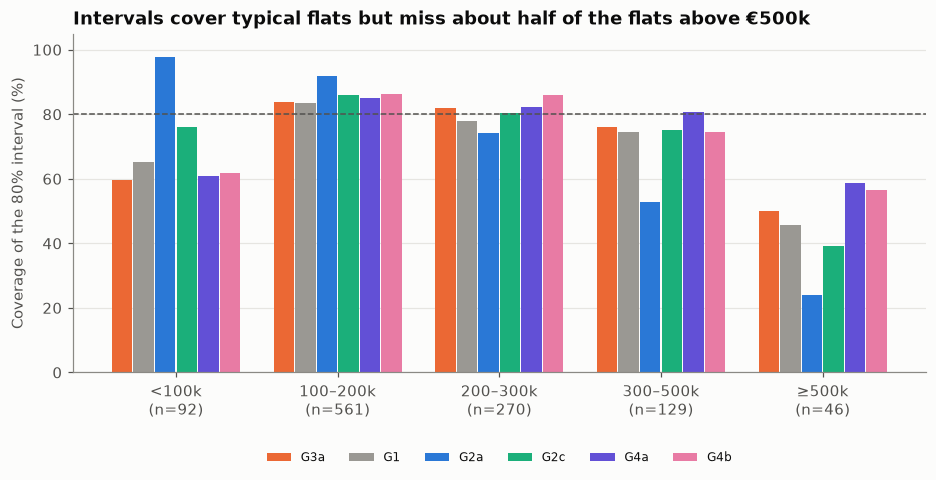

In [9]:
d = HP[HP['by'] == 'price_band']
bands = d.drop_duplicates('band')[['band', 'n']]
fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(len(bands)); w = 0.8 / len(SHOW)
cols = [vplot.ORANGE, vplot.GRAY, vplot.BLUE, vplot.AQUA, '#6250d6', '#e87ba4']
for j, m in enumerate(SHOW):
    v = d[d['method'] == m].set_index('band').reindex(bands['band'])['coverage']
    ax.bar(x + (j - (len(SHOW) - 1) / 2) * w, 100 * v, width=w * 0.95, color=cols[j], label=f'{m}')
ax.axhline(80, color=vplot.INK_2, ls='--', lw=1)
ax.set_xticks(x, [f'{b}\n(n={n})' for b, n in bands.values]); ax.set_ylabel('Coverage of the 80% interval (%)'); ax.set_ylim(0, 105)
ax.set_title('Intervals cover typical flats but miss about half of the flats above €500k'); ax.legend(ncols=len(SHOW), fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))
ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'ux_04_high_price_coverage'); plt.show()

**What it means** (actual price used only for this analysis, after the intervals were built):

| Price band | n | G3a coverage | G3a share above upper bound | G3a median width | G2a (absolute) coverage |
|---|---|---|---|---|---|
| < €100k | 92 | 0.60 | 7% | €50k | 0.98 |
| €100–200k | 561 | 0.84 | 4% | €92k | 0.92 |
| €200–300k | 270 | 0.82 | 14% | €156k | 0.74 |
| €300–500k | 129 | 0.76 | 22% | €275k | 0.53 |
| ≥ €500k | 46 | **0.50** | **50%** | €431k | 0.24 |

- **Every method misses expensive flats mostly from below.** Their asking price lies **above** the upper bound; the best (G4a) still has 41% above. This mirrors the underestimation found in the point predictions.
- **Even very wide intervals** (G3a median €431k for these flats) are not wide enough, because the inputs (area, rooms, city) cannot tell a luxury flat from an ordinary one of the same size.
- **Cheap flats** (< €100k) are partly missed from below the lower bound (G3a: 33% below). The methods pull their estimates up towards the typical flat.
- **Absolute vs relative intervals:** the absolute conformal interval (G2a) has the **same euro width (≈ €137k) for every flat**. It is far too wide for cheap flats (98% covered) and far too narrow for expensive ones (24% covered). **Relative and log-scale intervals (G2b, G2c, G3a, G4a) match the data much better**, because errors grow roughly in proportion to price.
- **Size:** flats ≥ 120 m² (n = 63): G3a covers 73%; the absolute interval only 40%.
- **No listings were removed** to improve these numbers.

## 9. Repeated listings and the exchangeability assumption

**What this code does:** Compares listing-level coverage with group-level coverage (each probable-duplicate group counted once), and checks whether listings in multi-listing groups are covered differently.

**Why we need it:** Conformal coverage assumes that calibration and new listings are exchangeable. Repeated adverts of the same flat are not independent. Groups are kept on one side of every split, but within-group dependence can still make listing-level coverage look more precise than it is.

In [10]:
o = OOF[(CHOSEN, 0.80)]; cov = (y >= o['lo']) & (y <= o['hi'])
multi = dev['repeat_group_size'] > 1
print(f'Listing-level coverage: {cov.mean():.3f} | group-level coverage (each group once): {pd.Series(cov).groupby(dev["repeat_group"].to_numpy()).mean().mean():.3f}')
print(f'Listings in multi-listing groups: n={multi.sum()} coverage {cov[multi].mean():.3f} | single listings: n={(~multi).sum()} coverage {cov[~multi].mean():.3f}')
print('Fold-to-fold coverage of the chosen method (80%):', F[(F.method == CHOSEN) & (F.level == 0.80)]['coverage'].round(3).tolist())

Listing-level coverage: 0.790 | group-level coverage (each group once): 0.787
Listings in multi-listing groups: n=132 coverage 0.826 | single listings: n=966 coverage 0.785
Fold-to-fold coverage of the chosen method (80%): [0.751, 0.839, 0.813, 0.779, 0.764]


**What it means:**
- **Coverage per listing vs per property:** listing-level coverage is 0.790 and group-level coverage is 0.787, practically identical. Treating probable repeats as separate listings does not distort the overall coverage.
- **Repeated listings:** the 132 listings in multi-listing groups are covered slightly more often (0.826) than single listings (0.785, n = 966). Repeated adverts tend to be ordinary new-build flats.
- **Fold variation:** coverage varies from **0.75 to 0.84** between folds. Any single 80% figure on about 220 listings carries roughly ±4 percentage points of sampling noise.
- **What the conformal methods (G2, G4) can and cannot claim:**
  - Split conformal guarantees average coverage only if calibration and new listings are **exchangeable**.
  - Our listings are a convenience sample from three platforms, with repeat groups (kept together, but still dependent within a group) and no time order.
  - So the 80% is an **empirical, cross-validated** coverage for listings like these. It is **not a formal guarantee**, and not a guarantee for any individual flat.
- **G3a has no finite-sample guarantee at all.** Its coverage is purely empirical, and that is how it is reported.

## 10. Secondary: listings for manual review

**What this code does:** Flags development listings whose asking price falls **outside the chosen method's 90% out-of-fold interval**, and listings with a robust within-city score |MAD z| > 3.5 of log €/m² (city medians and MADs from the training folds). It compares both with the student's own 'check' flags.

**Why we need it:** A listing far outside the range of similar flats is worth a second look: it may be a data error or a special property. Flags are **candidates for review**, never verdicts.

In [11]:
o90 = OOF[(CHOSEN, 0.90)]
flag_int = (y < o90['lo']) | (y > o90['hi'])
z = np.full(len(dev), np.nan); lppm = np.log(dev['price_eur'] / dev['area_m2']).to_numpy()
for k in range(5):
    tr, va = dev['cv_fold'] != k, (dev['cv_fold'] == k).to_numpy()
    s = pd.Series(lppm[tr.to_numpy()]).groupby(dev.loc[tr, 'city_clean'].to_numpy())
    cnt = s.size(); med = s.median(); mad = s.apply(lambda v: np.median(np.abs(v - np.median(v))))
    okc = cnt[(cnt >= ux.MIN_CITY) & (cnt.index != 'Unknown')].index
    gm, gmad = np.median(lppm[tr.to_numpy()]), np.median(np.abs(lppm[tr.to_numpy()] - np.median(lppm[tr.to_numpy()])))
    c = dev.loc[va, 'city_clean']
    m_ = c.map(med.reindex(okc)).fillna(gm).to_numpy(); d_ = c.map(mad.reindex(okc)).fillna(gmad).to_numpy()
    z[va] = (lppm[va] - m_) / (1.4826 * d_)
flag_mad = np.abs(z) > 3.5
chk = dev['source_check_flag'].eq('check').to_numpy()
summary = pd.DataFrame({'flag': ['outside 90% interval', '|MAD z| > 3.5', 'both'],
                        'n_flagged': [flag_int.sum(), flag_mad.sum(), (flag_int & flag_mad).sum()],
                        'share_%': [100 * flag_int.mean(), 100 * flag_mad.mean(), 100 * (flag_int & flag_mad).mean()],
                        'of which student check-flag': [(flag_int & chk).sum(), (flag_mad & chk).sum(), (flag_int & flag_mad & chk).sum()]})
display(summary.round(1)); print(f'Student check flags in development data: {chk.sum()}')
fl = dev.assign(flag_interval=flag_int, flag_mad=flag_mad)
display(pd.crosstab(fl['region'], [fl['flag_interval']], normalize='index').round(3).rename(columns={True: 'flagged share', False: 'not flagged'}))
display(pd.crosstab(fl['platform'], fl['flag_interval'], margins=True))
display(fl.groupby('price_band', observed=True)['flag_interval'].agg(['size', 'mean']).round(3))
fl.loc[flag_int | flag_mad, ['record_id', 'platform', 'city_clean', 'area_m2', 'rooms', 'price_eur', 'flag_interval', 'flag_mad']].to_csv(RES / 'review_candidates_dev.csv', index=False)

,flag,n_flagged,share_%,of which student check-flag
0,outside 90% interval,121,11.0,1
1,|MAD z| > 3.5,15,1.4,1
2,both,14,1.3,1


Student check flags in development data: 24


flag_interval,not flagged,flagged share
region,,
Unknown,0.926,0.074
coastal,0.888,0.112
continental,0.890,0.110


flag_interval,False,True,All
platform,,,
Estitor,293,33,326
Realitica,661,87,748
Realitica Adriatic,23,1,24
All,977,121,1098


,size,mean
price_band,,
<100k,92,0.326
100–200k,561,0.073
200–300k,270,0.074
300–500k,129,0.124
≥500k,46,0.304


**What this code does:** **Retrospective check.** Scores the 46 real apartment rows that cleaning removed for **known** problems (36 rentals, 7 misclassified types, 2 price conflicts, 1 invalid area) with the chosen method and MAD statistics fitted on **all development listings**. These rows never enter any fit. It also checks how often these rows already carried the student's check flag.

**Why we need it:** If the screening methods would have found the problems that we found by hand, they could help future data collection. These errors were already known, so this is a retrospective sanity check, not independent validation.

In [12]:
raw = vp.load_raw(FINAL / 'data' / 'raw' / vp.RAW_FILE)
sm, na = vp.load_settlement_mapping(FINAL / 'data' / 'reference' / 'settlement_mapping.csv')
real, _ = vp.clean_real_listings(raw, sm, na)
KNOWN = ['Rental listing (price < EUR 10,000)', 'Misclassified type (title says house / commercial)',
         'Data error: price conflicts with title (> 5%)', 'Invalid physical value (area < 15 m2)']
known = real[real['exclusion_reason'].isin(KNOWN)].copy()
assert not set(known['record_id']) & set(dev['record_id']) and len(known) == 46
lo, hi, c = ux.predict_interval(CHOSEN, dev, known, 0.10)
known['outside_90'] = (known['price_eur'] < lo) | (known['price_eur'] > hi)
s_all = pd.Series(lppm).groupby(dev['city_clean'].to_numpy()); cnt = s_all.size()
okc = cnt[(cnt >= ux.MIN_CITY) & (cnt.index != 'Unknown')].index
med = s_all.median().reindex(okc); mad = s_all.apply(lambda v: np.median(np.abs(v - np.median(v)))).reindex(okc)
gm, gmad = np.median(lppm), np.median(np.abs(lppm - np.median(lppm)))
kz = (np.log(known['price_eur'] / known['area_m2']) - known['city_clean'].map(med).fillna(gm)) / (1.4826 * known['city_clean'].map(mad).fillna(gmad))
known['mad_flag'] = kz.abs() > 3.5
known['student_check_flag'] = ~known['provjera'].map(vp.norm).str.startswith('ok')
rk = known.groupby('exclusion_reason').agg(n=('record_id', 'size'), outside_90=('outside_90', 'sum'), mad_flag=('mad_flag', 'sum'), student_flag=('student_check_flag', 'sum'))
display(rk); rk.to_csv(RES / 'retrospective_known_errors.csv')

,n,outside_90,mad_flag,student_flag
exclusion_reason,,,,
Data error: price conflicts with title (> 5%),2,2,1,0
Invalid physical value (area < 15 m2),1,1,1,1
Misclassified type (title says house / commercial),7,3,2,0
"Rental listing (price < EUR 10,000)",36,36,36,36


**What it means:**
- **Development listings flagged:**
  - 121 (11.0%) fall outside G3a's 90% out-of-fold interval, close to the expected 10%;
  - 15 (1.4%) have |MAD z| > 3.5; 14 of these are flagged by both methods.
- **The interval flags are dominated by price tails:** 33% of flats < €100k and 30% of flats ≥ €500k are flagged, against 7% in the middle bands. They mostly identify *legitimately unusual* listings, not errors.
- **Weak labels barely agree:** only **1 of the 24** development listings that the student marked "check" is flagged. The student's flags and the statistical flags capture different things.
- **Retrospective check on the 46 known errors** (all removed earlier, never used for fitting):

| Known problem | n | Outside 90% interval | MAD flag | Already flagged by the student |
|---|---|---|---|---|
| Rental (price < €10k) | 36 | 36 | 36 | 36 |
| Price conflicts with the title | 2 | 2 | 1 | 0 |
| Invalid area (1 m²) | 1 | 1 | 1 | 1 |
| Misclassified type (title says house) | 7 | 3 | 2 | 0 |

- The screening finds the **gross errors**. These are also found by a simple price rule or by the student's own check, and they were found by hand during cleaning, so this is a retrospective sanity check, **not independent validation**.
- It finds only 3 of the 7 misclassified houses, whose prices look plausible for flats.
- **Isolation Forest was not run** (as decided in the plan): the labels are too few and too easy to validate it reliably.
- **Conclusion:** the statistical screening adds little beyond simple rules. Flags are **candidates for manual review only**, never "overpriced", "underpriced", "bargain" or "fraud". **This is future work, not a Capstone result.**

## 11. Demonstrations on hypothetical apartments

**What this code does:** Fits the chosen method on all 1,098 development listings and predicts 80% and 90% ranges for five hypothetical flats. For each flat it shows how many similar development listings exist (same city, area within ±15%) and the method's out-of-fold coverage in that city.

**Why we need it:** Concrete examples make the ranges understandable. These are **illustrations of asking-price ranges** produced by a trained method. They are not valuations, and not evaluations on real listings.

In [13]:
EX = pd.DataFrame({'city_clean': ['Podgorica', 'Podgorica', 'Budva', 'Nikšić', 'Tivat'], 'area_m2': [45.0, 70.0, 70.0, 70.0, 100.0]})
sup, rooms = [], []
for _, r in EX.iterrows():
    w = dev[(dev['city_clean'] == r.city_clean) & dev['area_m2'].between(0.85 * r.area_m2, 1.15 * r.area_m2)]
    sup.append(len(w)); rooms.append(float(w['rooms'].median()) if w['rooms'].notna().any() else np.nan)
EX['similar_dev_listings'] = sup; EX['rooms'] = rooms
for lv, alpha in LEVELS.items():
    lo, hi, c = ux.predict_interval(CHOSEN, dev, EX, alpha)
    EX[f'low_{int(lv*100)}'], EX[f'high_{int(lv*100)}'] = lo.round(-3), hi.round(-3)
EX['central'] = c.round(-3)
cov_city = city[city['method'] == CHOSEN].set_index('city_clean')['coverage']
EX['cv_coverage_80_in_city'] = EX['city_clean'].map(cov_city).round(2)
EX['note'] = np.where(EX['similar_dev_listings'] < 10, 'few similar listings: rough indication only', '')
display(EX); EX.to_csv(RES / 'demonstrations.csv', index=False)

,city_clean,area_m2,similar_dev_listings,rooms,low_80,high_80,low_90,high_90,central,cv_coverage_80_in_city,note
0,Podgorica,45.0,114,1.0,104000.0,172000.0,97000.0,177000.0,129000.0,0.79,
1,Podgorica,70.0,133,2.0,149000.0,257000.0,140000.0,272000.0,194000.0,0.79,
2,Budva,70.0,33,2.0,174000.0,373000.0,154000.0,429000.0,247000.0,0.81,
3,Nikšić,70.0,12,2.0,102000.0,163000.0,98000.0,180000.0,132000.0,0.79,
4,Tivat,100.0,6,2.0,298000.0,693000.0,282000.0,803000.0,381000.0,0.79,few similar listings: rough indication only


**What this code does:** Draws the five example ranges (80% as a thick bar, 90% as a thin line, central estimate as a dot).

**Why we need it:** A presentation-ready picture of what the method produces for typical flats.

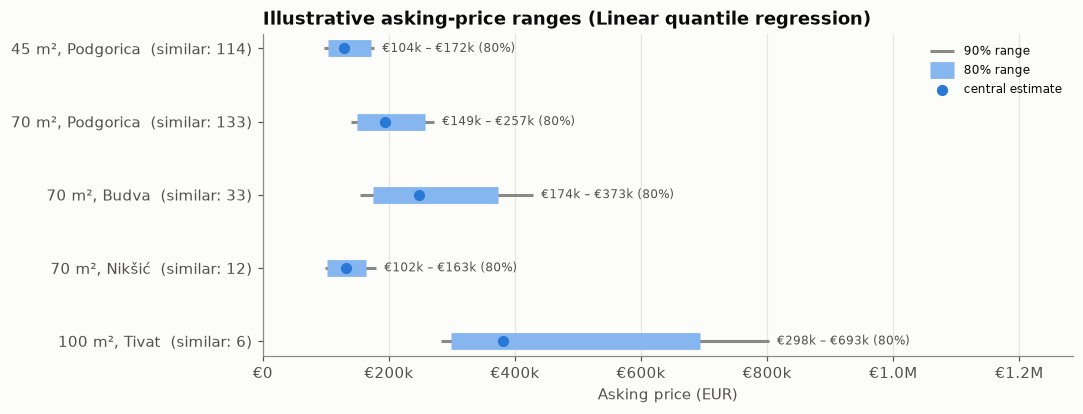

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 3.8)); yy = np.arange(len(EX))[::-1]
ax.hlines(yy, EX['low_90'], EX['high_90'], color=vplot.INK_3, lw=2, label='90% range')
ax.hlines(yy, EX['low_80'], EX['high_80'], color='#86b6ef', lw=11, label='80% range')
ax.scatter(EX['central'], yy, color=vplot.BLUE, s=40, zorder=3, label='central estimate')
for yi, r in zip(yy, EX.itertuples()):
    ax.text(r.high_90, yi, f"  €{r.low_80/1000:.0f}k – €{r.high_80/1000:.0f}k (80%)", va='center', fontsize=8, color=vplot.INK_2)
ax.set_yticks(yy, [f'{r.area_m2:.0f} m², {r.city_clean}  (similar: {r.similar_dev_listings})' for r in EX.itertuples()])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro)); ax.set_xlabel('Asking price (EUR)')
ax.set_xlim(0, EX['high_90'].max() * 1.6)
ax.set_title(f'Illustrative asking-price ranges ({ux.LABELS[CHOSEN]})'); ax.legend(loc='upper right', fontsize=8); ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'ux_05_example_ranges'); plt.show()

**What it means** (G3a fitted on all 1,098 development listings; hypothetical flats, not real listings):

| Flat | Similar dev listings* | Central estimate | 80% range | 90% range | CV coverage in that city |
|---|---|---|---|---|---|
| 45 m², Podgorica (1 room) | 114 | €129k | €104k – €172k | €97k – €177k | 0.79 |
| 70 m², Podgorica (2 rooms) | 133 | €194k | €149k – €257k | €140k – €272k | 0.79 |
| 70 m², Budva (2 rooms) | 33 | €247k | €174k – €373k | €154k – €429k | 0.81 |
| 70 m², Nikšić (2 rooms) | 12 | €132k | €102k – €163k | €98k – €180k | 0.79 |
| 100 m², Tivat (2 rooms) | **6** ⚠️ | €381k | €298k – €693k | €282k – €803k | 0.79 |

\* Same city, area within ±15%. "Rooms" is the median room count of those similar listings, because the method needs it as an input.

- The same 70 m² flat has a range about **twice as wide in Budva** (€199k) as in **Podgorica** (€108k) or **Nikšić** (€61k). This reflects the much larger spread of coastal asking prices.
- **The 100 m² Tivat example has only 6 similar development listings.** Its range is a rough indication only.
- **How to read a range:** a cross-validated 80% interval for **one flat's asking price**. Among development listings like these, about 8 in 10 fell inside such ranges. It is **not** a confidence interval for the average price, **not** a guarantee for this particular flat, and **not** a valuation.

## 12. Answers and recommendation

| # | Question | Answer (exploratory CV, development data) |
|---|---|---|
| 1 | Can we predict useful ranges of asking prices? | **Partly.** Honest 80% ranges are achievable (78.9% coverage, similar in every city). They are *moderately* wide overall (median 64% of the estimate): fairly informative in continental cities (40–55%), wide on the coast (80–97%), and unreliable for flats ≥ €500k (50% coverage). |
| 2 | Which method balances coverage and width best? | **G3a, linear quantile regression on log price.** Best interval score, acceptable coverage, even coverage across cities. G1 (empirical city €/m² quantiles) is the simplest close alternative, but it covers less evenly. |
| 3 | Does quantile regression add value? | **Yes, for ranges** (not for the point estimate). Its width adapts to city and size, which gives the most even city-level coverage. The gradient-boosting version under-covers (74.6%) and adds nothing. |
| 4 | Does conformal prediction improve reliability? | **Overall coverage, yes** (all conformal variants ≈ 80–82%). **City-level reliability, no:** one-size widths over-cover Podgorica and under-cover the coast. CQR adds little to linear quantile regression, which is already well calibrated. There is no formal guarantee here (exchangeability is doubtful). |
| 5 | Where are the estimates most reliable? | Coverage is similar everywhere for G3a. The ranges are **most informative** (narrowest) in **Nikšić, Cetinje, Podgorica and Kolašin**, and least informative in **Tivat, Budva and Herceg Novi**. Small cities have too few listings for firm conclusions. |
| 6 | How wide are intervals for expensive flats? | For flats ≥ €500k: median 80% width ≈ **€431k**, yet only **50%** are covered, and the other half lie above the upper bound. |
| 7 | Can we flag listings for manual review? | Gross errors, yes, but simple rules and the student's own checks already catch them. Statistical flags mostly mark legitimately extreme prices and agree with the student's flags in 1 of 24 cases. **Future work, not a Capstone result.** |
| 8 | What should the presentation include? | (1) Coverage vs width chart; (2) city reliability and width chart; (3) example ranges; (4) high-price coverage chart. **Key message:** *"An honest estimate is a range: about ±25% in continental cities and ±40–50% on the coast. Ranges are reliable for typical flats but miss half of the flats above €500k."* |
| 9 | Which research question fits the findings? | *How accurately can we estimate apartment asking prices in Montenegro, and how reliably can we quantify the uncertainty of these predictions?* It fits: accuracy is about €51k MAE (≈ 16% typical error); uncertainty can be quantified honestly with about 80% coverage, at a width that depends strongly on location. It must be stated that the interval question was added after the earlier phases. |
| 10 | Should this be included in the final notebooks? | **Recommended, as a compact addition.** For example, a sub-section of `02_modelling.ipynb` (sections 9–10) with G1 and G3a only, their CV coverage and width, the city chart and the example ranges, all labelled exploratory. **Optional, needs your approval:** the 278 test listings were never used for interval methods, so a **single, pre-registered test evaluation of G3a and G1** would be the most honest available check of these ranges (the test set has been seen for point predictions, but never for intervals). |